# 11 · Coupled systems and DAEs

Engineering models rarely come as a single PDE: a fluid phase exchanges with a solid phase at every point, two
streams flow in opposite directions, a reaction couples species. The method of lines stacks all the unknowns
into one state vector; the only new question is the band structure of the Jacobian. And when some equations
have no time derivative - boundary conditions, equilibrium relations, algebraic constraints - the system is a
differential-algebraic equation, which the BDF family handles directly. This notebook works through an
adsorption column, a catalyst pellet, a counterflow exchanger, and the heat equation as a DAE.

**What you will learn**
- stack coupled PDE-ODE systems into one state and find the Jacobian band
- check coupled problems by global balances
- handle streams in opposite directions
- write boundary conditions and constraints as algebraic equations and solve the DAE

**Before you start:** notebooks 03 and 07  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, linalg as la
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## A packed-bed adsorber: PDE + ODE at every point

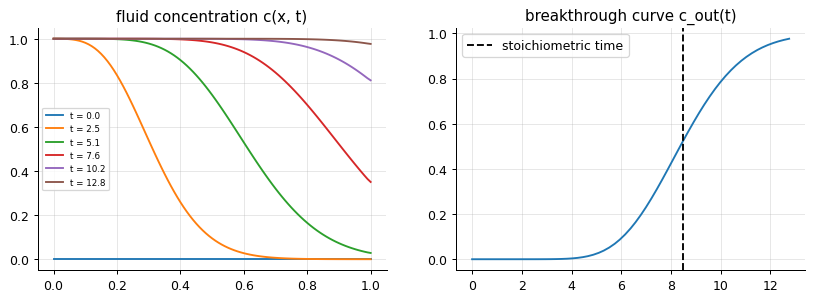

breakthrough at c_out = 0.5: t = 8.37 (stoichiometric 8.50); mass balance fed 12.750 = out 4.280 + held 8.479 (residual -8.2e-03)
state size 202, Jacobian band 102 (q_i couples to c_i at index i + n): 1 Jacobian for 638 steps


In [2]:
p = pr.packed_bed_adsorber(K=5.0)
s = p.solve("bdf", 0.02, order=2, n_out=60)
n = 101
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i in range(0, 61, 12):
    axes[0].plot(p.x, s.y[i][:n], label=f"t = {s.t[i]:.1f}")
axes[0].set_title("fluid concentration c(x, t)"); axes[0].legend(fontsize=7)
axes[1].plot(s.t, s.y[:, n - 1]); axes[1].axvline(p.params["t_stoich"], color="k", ls="--", label="stoichiometric time"); axes[1].set_title("breakthrough curve c_out(t)"); axes[1].legend()
plt.show()
fed = p.params["u"] * s.t[-1]; out = np.sum(0.5 * (s.y[1:, n - 1] + s.y[:-1, n - 1]) * p.params["u"] * np.diff(s.t))
held = p.grid.integrate(s.y[-1][:n]) + p.params["ratio"] * p.grid.integrate(s.y[-1][n:])
print(f"breakthrough at c_out = 0.5: t = {np.interp(0.5, s.y[:, n - 1], s.t):.2f} (stoichiometric {p.params['t_stoich']:.2f}); mass balance fed {fed:.3f} = out {out:.3f} + held {held:.3f} (residual {fed - out - held:+.1e})")
print(f"state size {2 * n}, Jacobian band {p.band[0]} (q_i couples to c_i at index i + n): {s.jacobian_evaluations} Jacobian for {s.steps} steps")

The column's state is [c, q]: the fluid concentration obeys an advection-diffusion PDE with a sink, the solid
loading an ODE at each point. Stacked, the Jacobian has a band of n + 2 - the coupling between c_i and q_i sits
n positions off the diagonal - still cheap. The breakthrough front arrives at the stoichiometric time
L(1 + (1 − ε)K/ε)/u that a mass balance predicts, and the overall balance (fed = out + held) closes.

## A catalyst pellet: steady effectiveness from a transient

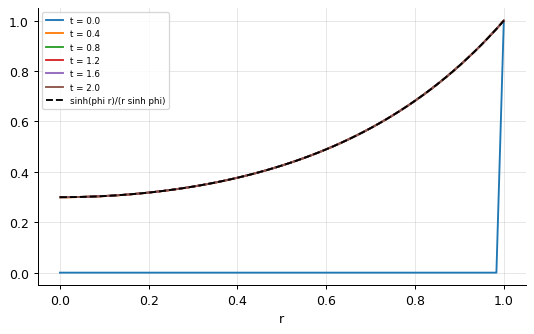

effectiveness factor from the surface flux: 0.6712 vs 3 (phi coth phi - 1)/phi^2 = 0.6716


In [3]:
p = pr.catalyst_pellet(phi=3.0)
s = p.solve("bdf", 0.005, order=2, n_out=5)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.1f}")
plt.plot(p.x, p.exact(p.x), "k--", label="sinh(phi r)/(r sinh phi)"); plt.legend(fontsize=7); plt.xlabel("r"); plt.show()
c = s.y[-1]; flux = (3 * c[-1] - 4 * c[-2] + c[-3]) / (2 * p.grid.dx)
print(f"effectiveness factor from the surface flux: {3 * flux / p.params['phi']**2:.4f} vs 3 (phi coth phi - 1)/phi^2 = {p.params['eta']:.4f}")

Diffusion and first-order reaction in a sphere: the steady profile sinh(φr)/(r sinh φ) is reached from an
empty start, and the effectiveness factor - reaction rate relative to a pellet at surface concentration -
follows from the surface flux (a second-order one-sided difference) to 0.1 %.

## Counterflow: two streams, two upwind directions

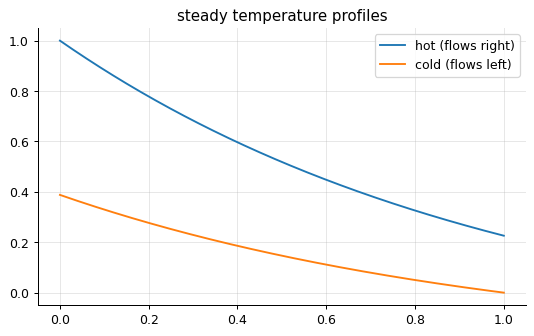

effectiveness 1 - T_h(1) = 0.7740 vs the NTU relation 0.7746


In [4]:
p = pr.counterflow_exchanger(n=400, NTU=2.0, Cr=0.5)
s = p.solve("bdf", 0.01, order=2)
n = 401
plt.plot(p.x, s.y[-1][:n], label="hot (flows right)"); plt.plot(p.x, s.y[-1][n:], label="cold (flows left)"); plt.legend(); plt.title("steady temperature profiles"); plt.show()
print(f"effectiveness 1 - T_h(1) = {1 - s.y[-1][n - 1]:.4f} vs the NTU relation {p.params['effectiveness']:.4f}")

Each stream is an advection equation with its own upwind direction and its own inlet; the exchange term
couples them. A detail worth remembering: a source term added *after* an operator has imposed a Dirichlet
inlet must not move the inlet - the problem re-pins the inlet rows - or the steady state is wrong (the
effectiveness came out at 0.92 instead of 0.77 before that line was added).

## The heat equation as a DAE

In [5]:
p = pr.heat_as_dae()
sd = ti.dae_bdf(p.params["F"], p.y0, (0, 1.0), 0.005, order=2, band=(1, 1))
sr = ti.bdf(p.rhs, p.y0, (0, 1.0), 0.005, 2, band=(1, 1))
print(f"DAE formulation vs ghost-point ODE formulation: max difference {np.max(np.abs(sd.y[-1] - sr.y[-1])):.1e}")
print(f"the algebraic equation u_0 - sin(pi t) = 0 holds at every output to {np.max(np.abs(sd.y[:, 0] - np.sin(np.pi * sd.t))):.1e}")
print(sd, "\n(this simple DAE solver refreshes its Jacobian at every step)")

DAE formulation vs ghost-point ODE formulation: max difference 1.5e-05
the algebraic equation u_0 - sin(pi t) = 0 holds at every output to 5.6e-25
Solution(t in [0, 1], 11 outputs, state size 41, steps=200, rejected=0, evaluations=0, newton=400, jacobians=200, 'ok') 
(this simple DAE solver refreshes its Jacobian at every step)


Writing the boundary condition as an algebraic equation 0 = u₀ − g(t) and solving the whole system
F(t, y, y′) = 0 with a fully implicit BDF is the DAE view of the method of lines: boundary conditions, algebraic
constraints and equilibrium relations all become rows without derivatives. For an index-1 system (the
algebraic variables are determined by the differential ones) BDF converges at its usual order, and the
constraint is satisfied exactly at every step - the formulation to reach for when a boundary condition is
implicit, nonlinear, or couples several unknowns.

## Inside the algorithm: the band of a coupled Jacobian

Jacobian of the exchanger: nonzeros within 401 of the diagonal (the coupling T_h,i <-> T_c,i sits n + 1 = 401 off)


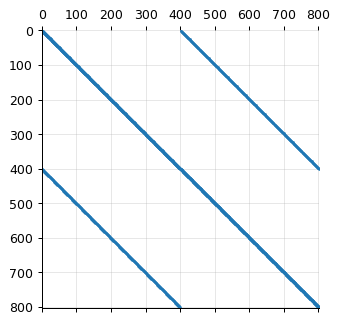

In [6]:
pe = pr.counterflow_exchanger(n=400)
J = la.dense_jacobian(lambda y: pe.rhs(0.0, y), pe.y0 + 0.1)
nz = np.abs(J) > 1e-9
rows, cols = np.where(nz)
print(f"Jacobian of the exchanger: nonzeros within {np.max(np.abs(rows - cols))} of the diagonal (the coupling T_h,i <-> T_c,i sits n + 1 = 401 off)")
plt.spy(nz, markersize=1); plt.show()

## Exercises
1. Replace the adsorber's linear isotherm by a Langmuir isotherm q* = q_max K c/(1 + K c). Does the front sharpen or spread (a favourable isotherm sharpens it)? Measure the breakthrough curve's width.
2. Write the catalyst-pellet problem as a DAE with a film-resistance boundary condition at the surface: 0 = Sh (1 - c_s) - c_r(1). Solve with `dae_bdf` and compare the effectiveness with the no-resistance case.
3. **Implement it yourself:** add a second adsorbing species with a different K to the column and show that the two breakthrough fronts travel at their own stoichiometric speeds.